# Gaia host-star comparisons

I compare measured orbital periods with host-star distance and vertical velocity using a bounded NASA Exoplanet Archive excerpt matched to Gaia DR3. Each star contributes one point, the median positive measured period among its supplied planets. A multi-planet system does not supply independent stellar velocities.

The excerpt is limited to 100 default-solution planet rows in the archive response order. It is neither a random nor a volume-complete sample. Incomplete six-dimensional measurements and parallax fractional errors above 0.2 are excluded by the phase-space calculation. Distances use positive inverse parallaxes without a zero-point correction. Coordinates and velocities have Galactic axes and a Solar System barycentre origin at the reported Gaia reference epoch.

The two comparisons below are descriptive. No p-values, measurement-error propagation, survey-completeness correction, or causal interpretation is supplied. The within-host median describes only the downloaded planet rows.

In [1]:
from datetime import datetime, timezone
from pathlib import Path
import os
import re
import socket
import warnings

import pandas as pd
from IPython.display import Image, display
from tdpy.verbosity import print

with warnings.catch_warnings(record=True) as import_warnings:
    from pergamon.exoplanet_catalog import load_confirmed_exoplanets
    from pergamon.gaia_kinematics import (
        load_gaia_dr3_astrometry,
        attach_gaia_phase_space,
        host_phase_space_rank_correlation,
        plot_host_phase_space_rank_correlation,
    )
for warning in import_warnings:
    display(f'{warning.category.__name__}: {warning.message}')

example_directory = next((candidate for candidate in (Path('.'), Path('examples'))
                          if (candidate / 'gaia_host_correlations.ipynb').is_file()), None)
if example_directory is None:
    raise ValueError('Run the notebook from the Pergamon repository or its examples directory')
row_limit = 100
snapshot_tag = os.environ.get('PERGAMON_GAIA_SNAPSHOT_TAG')
if snapshot_tag:
    if not re.fullmatch(r'\d{8}_\d{6}', snapshot_tag):
        raise ValueError('Snapshot tag must use YYYYMMDD_HHMMSS')
    datetime.strptime(snapshot_tag, '%Y%m%d_%H%M%S')
    source_directory = example_directory / '..' / 'data'
    planet_path = source_directory / f'gaia_archive_planets_{snapshot_tag}.csv'
    astrometry_path = source_directory / f'gaia_dr3_astrometry_{snapshot_tag}.csv'
    print(f'Reading from {planet_path}...')
    planets = pd.read_csv(planet_path, dtype={'gaia_dr3_id': 'string'})
    print(f'Reading from {astrometry_path}...')
    astrometry = pd.read_csv(astrometry_path, dtype={'source_id': 'string'})
else:
    network_timeout_seconds = 30  # [s]
    previous_timeout = socket.getdefaulttimeout()
    try:
        socket.setdefaulttimeout(network_timeout_seconds)
        planets = load_confirmed_exoplanets(limit=row_limit)
        astrometry = load_gaia_dr3_astrometry(planets['gaia_dr3_id'])
    finally:
        socket.setdefaulttimeout(previous_timeout)
joined = attach_gaia_phase_space(planets, astrometry)
display(pd.DataFrame({
    'input_mode': ['retained snapshot' if snapshot_tag else 'live archive excerpt'],
    'planet_rows': [len(planets)],
    'matched_gaia_stars': [len(astrometry)],
    'complete_6d_planet_rows': [int(joined['gaia_6d_available'].sum())],
}))
display(joined['gaia_6d_status'].value_counts().rename_axis('phase_space_status').to_frame('planet_rows'))

,input_mode,planet_rows,matched_gaia_stars,complete_6d_planet_rows
0,retained snapshot,100,82,86


,planet_rows
phase_space_status,
complete,86
incomplete_astrometry,11
unmatched,3


In [2]:
comparisons = {
    'period_distance': host_phase_space_rank_correlation(
        joined, 'pl_orbper', 'gaia_inverse_parallax_distance_pc',
    ),
    'period_vertical_velocity': host_phase_space_rank_correlation(
        joined, 'pl_orbper', 'gaia_barycentric_galactic_vz_km_s',
    ),
}
comparison_table = pd.DataFrame([
    {'comparison': name, **{key: result[key] for key in (
        'n_input_planets', 'n_used_planets', 'n_hosts', 'spearman_rho', 'status',
    )}}
    for name, result in comparisons.items()
])
display(comparison_table.round({'spearman_rho': 2}))
display(comparisons['period_distance']['hosts'].head())

,comparison,n_input_planets,n_used_planets,n_hosts,spearman_rho,status
0,period_distance,100,86,73,0.1,descriptive_only
1,period_vertical_velocity,100,86,73,-0.0,descriptive_only


,gaia_source_id,planet_value,host_value,measured_planet_count,gaia_source_url,gaia_retrieved_at_utc
0,2086468453545432960,2.735926,610.560535,1,https://gea.esac.esa.int/tap-server/tap/sync?R...,2026-10-24T00:44:40.085748+00:00
1,2086636884980514304,3.234700,584.527586,1,https://gea.esac.esa.int/tap-server/tap/sync?R...,2026-10-24T00:44:40.085748+00:00
2,2099925719951103872,1.592851,631.989134,1,https://gea.esac.esa.int/tap-server/tap/sync?R...,2026-10-24T00:44:40.085748+00:00
3,2102468134431912064,4.225385,640.155795,1,https://gea.esac.esa.int/tap-server/tap/sync?R...,2026-10-24T00:44:40.085748+00:00
4,2102548708017562112,10.854077,286.236927,1,https://gea.esac.esa.int/tap-server/tap/sync?R...,2026-10-24T00:44:40.085748+00:00


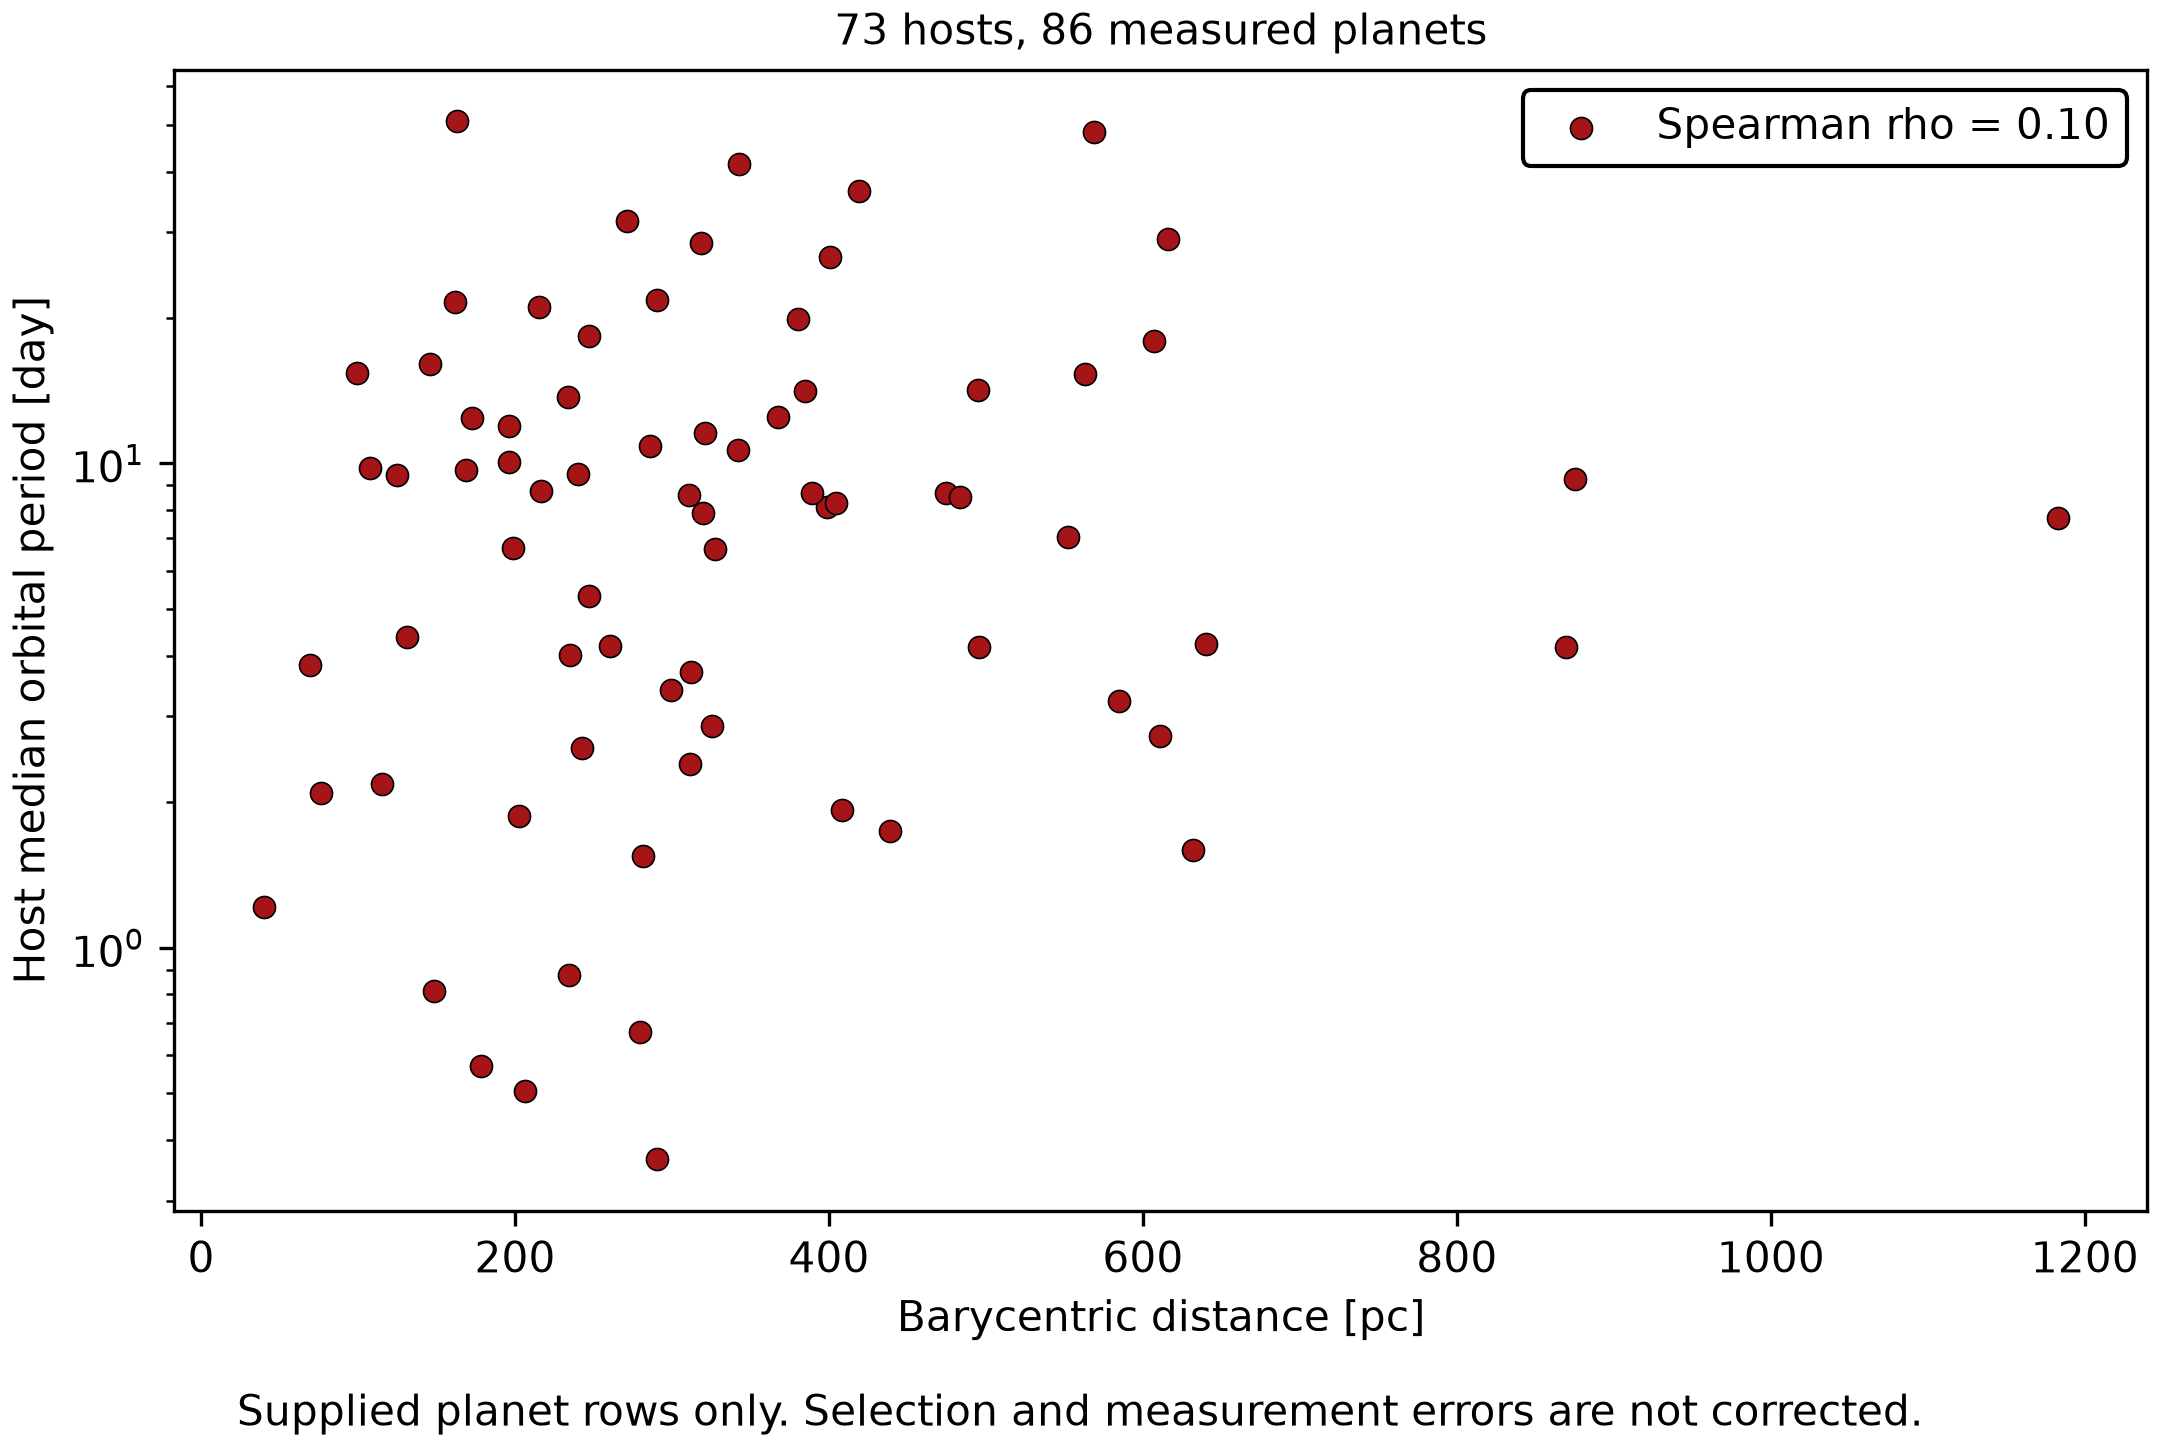

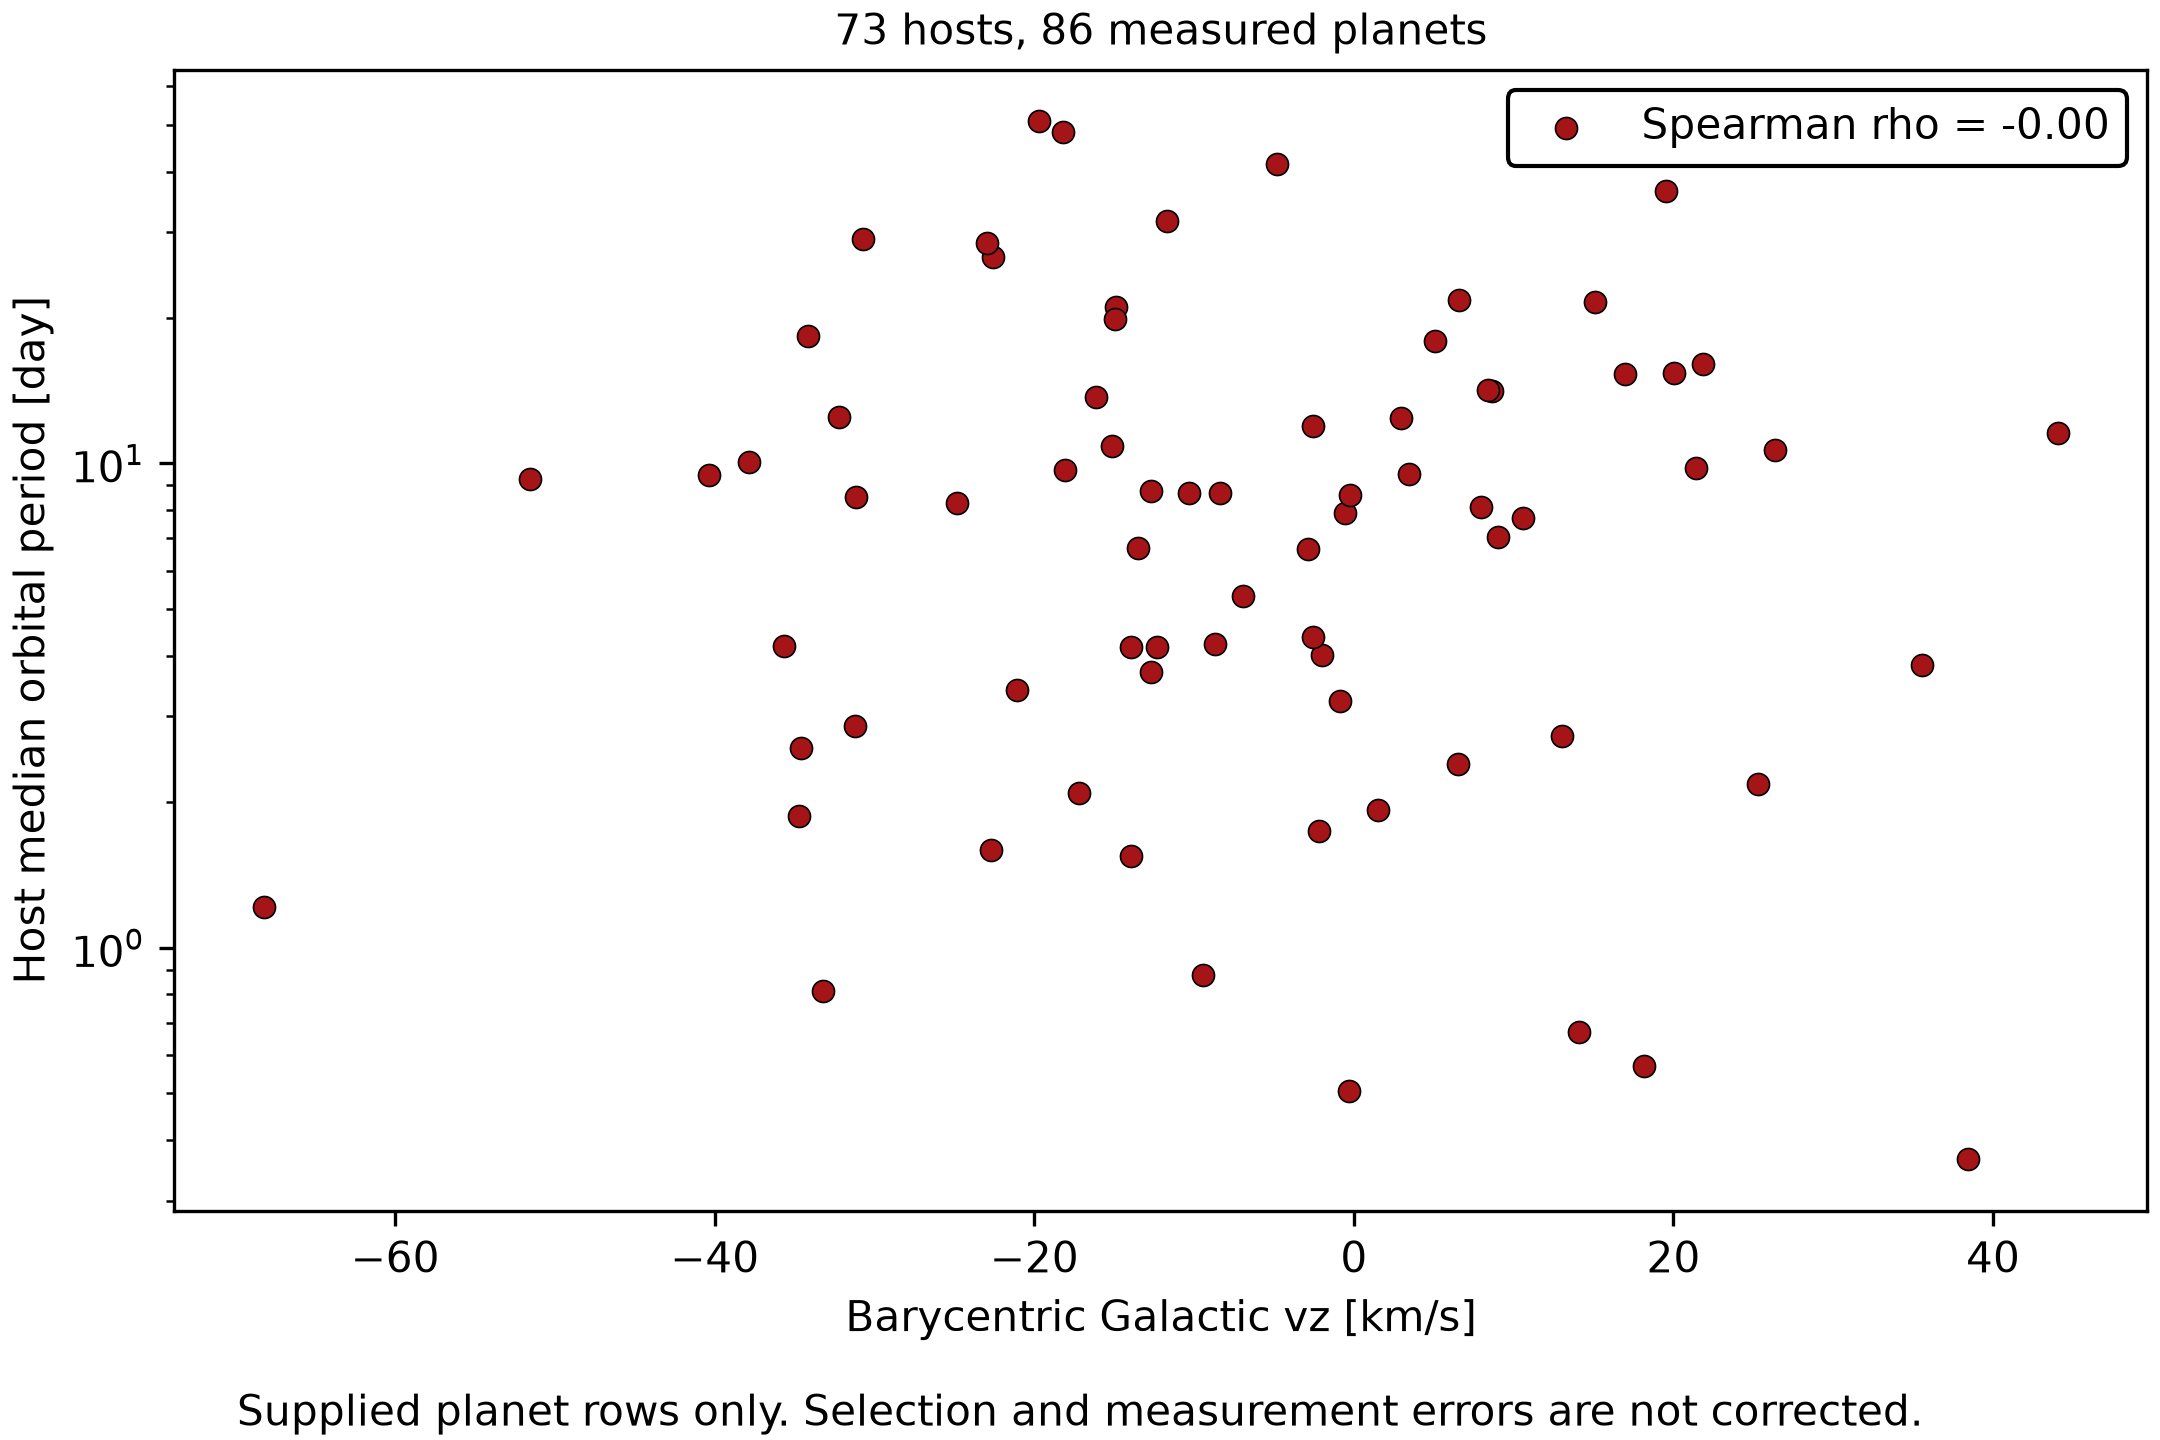

In [3]:
example_directory = next((candidate for candidate in (Path('.'), Path('examples'))
                          if (candidate / 'gaia_host_correlations.ipynb').is_file()), None)
if example_directory is None:
    raise ValueError('Run the notebook from the Pergamon repository or its examples directory')
time_tag = datetime.now(timezone.utc).strftime('%Y%m%d_%H%M%S')
data_directory = example_directory / '..' / 'data'
data_directory.mkdir(parents=True, exist_ok=True)
retained_tables = {
    'archive_planets': planets,
    'dr3_astrometry': astrometry,
    'joined_planets': joined,
    'host_comparisons': comparison_table,
    **{name + '_hosts': result['hosts'] for name, result in comparisons.items()},
}
for name, table in retained_tables.items():
    path = data_directory / f'gaia_{name}_{time_tag}.csv'
    print(f'Writing to {path}...')
    table.to_csv(path, index=False, mode='x')

plot_paths = {}
for name, result in comparisons.items():
    plot_paths[name] = plot_host_phase_space_rank_correlation(
        result, example_directory / 'visuals', write_bokeh=True, time_tag=time_tag,
    )
    display(Image(filename=str(plot_paths[name]['static']),
                  alt=f"Median measured orbital period for {result['n_hosts']} Gaia hosts against "
                      f"{result['phase_space_column']}. One point per host in the bounded archive excerpt."))

## What the comparison establishes

The tables and figures show the rank association within the measured host subset of this particular archive response. The coefficient alone cannot establish either a physical relation or its absence. Host grouping prevents repeated planet rows from increasing the number of independent stars, but it does not correct the archive's heterogeneous discovery selection or Gaia's radial-velocity selection.

The host median depends on which confirmed planets occur in the downloaded excerpt. It must not be read as the innermost period or the median of a complete planetary system. Distance errors are approximated by the stated parallax precision cut, rather than propagated through the coordinate calculation. Vertical velocities are barycentric, with no Solar-motion subtraction.

No stellar density, age, chemical abundance, Galactic orbit, past encounter, or dynamical-history measurement is inferred here. Those questions require additional sourced measurements, an explicit dynamical model, propagated uncertainties, and a defined target selection. Each run retains the archive rows, Gaia measurements, joined table, host medians, and coefficients in timestamped CSV snapshots. The optional HTML figures contain the same plotted host rows as the static images.